# Retail Demand Forecasting System

**Business Problem**

Retail companies must predict:<br>
__✅ future product demand__

Why?
Because businesses need to:
- manage inventory
- avoid overstock
- avoid stockouts
- optimize warehouse planning
- improve revenue

## PHASE 1 — Retail Data Understanding & Sales Analysis

### Step 1 — Import Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

### Step 2 — Load Dataset

In [3]:
df = pd.read_csv("data/Walmart.csv")

### Step 3 — View First Rows

In [4]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


### Step 4 — Dataset Shape

In [5]:
df.shape

(6435, 8)

### Step 5 — Column Names

In [6]:
df.columns

Index(['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment'],
      dtype='object')

### Step 6 — Dataset Info

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


### Step 7 — Statistical Summary

In [8]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


### Step 8 — Missing Values Check

In [9]:
df.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

### Step 9 — Duplicate Rows Check

In [10]:
df.duplicated().sum()

np.int64(0)

### Step 10 — Convert Date Column

In [11]:
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True
)

### Step 11 — Verify Date Conversion

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


### Step 12 — Weekly Sales Distribution

**Important Observation**

Check:
- skewness
- high sales outliers
- demand concentration

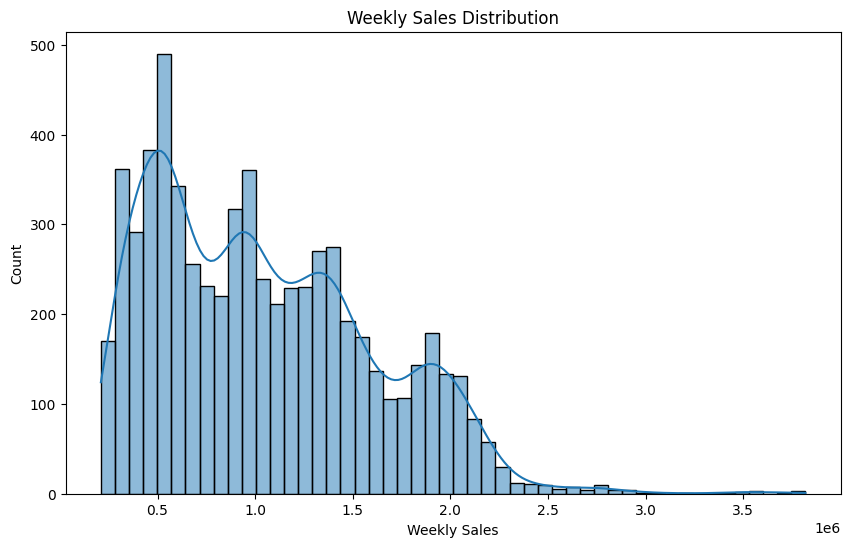

In [14]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Weekly_Sales"],
    bins=50,
    kde=True
)

plt.title("Weekly Sales Distribution")

plt.xlabel("Weekly Sales")

plt.show()

### Step 13 — Sales Trend Over Time

**Business Insights**

Observe:
- seasonal spikes
- demand fluctuations
- sales trend movement

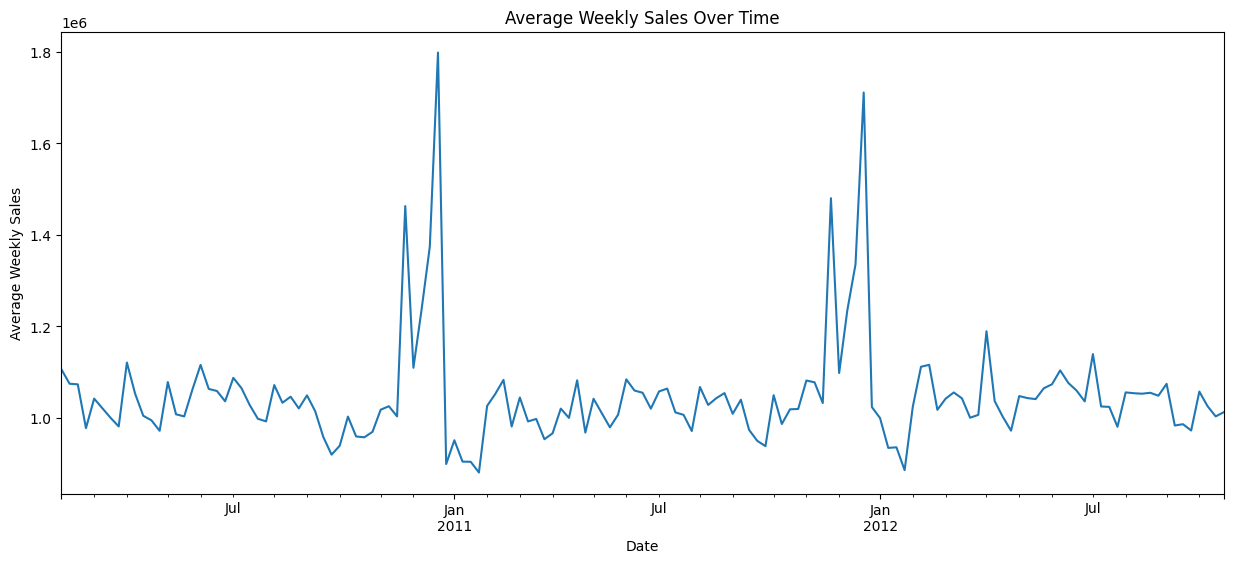

In [15]:
plt.figure(figsize=(15,6))

df.groupby("Date")["Weekly_Sales"].mean().plot()

plt.title("Average Weekly Sales Over Time")

plt.xlabel("Date")

plt.ylabel("Average Weekly Sales")

plt.show()

### Step 14 — Holiday Impact Analysis

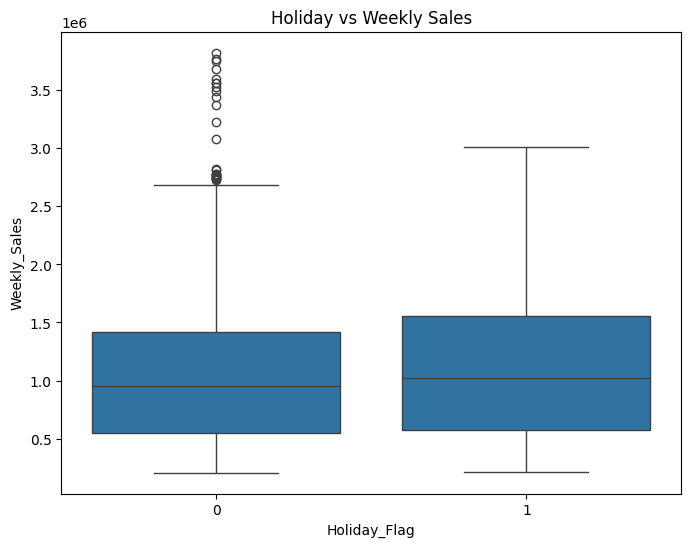

In [16]:
plt.figure(figsize=(8,6))

sns.boxplot(
    x="Holiday_Flag",
    y="Weekly_Sales",
    data=df
)

plt.title("Holiday vs Weekly Sales")

plt.show()

### Step 15 — Store-wise Sales Analysis

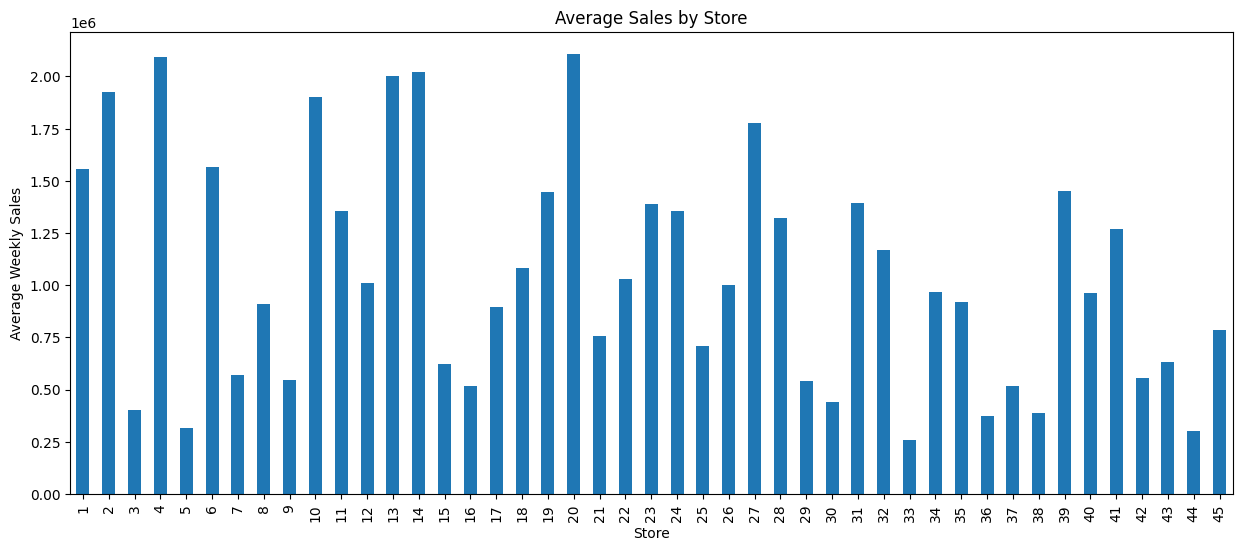

In [17]:
plt.figure(figsize=(15,6))

store_sales = df.groupby("Store")[
    "Weekly_Sales"
].mean()

store_sales.plot(kind="bar")

plt.title("Average Sales by Store")

plt.xlabel("Store")

plt.ylabel("Average Weekly Sales")

plt.show()

### Step 16 — Correlation Heatmap

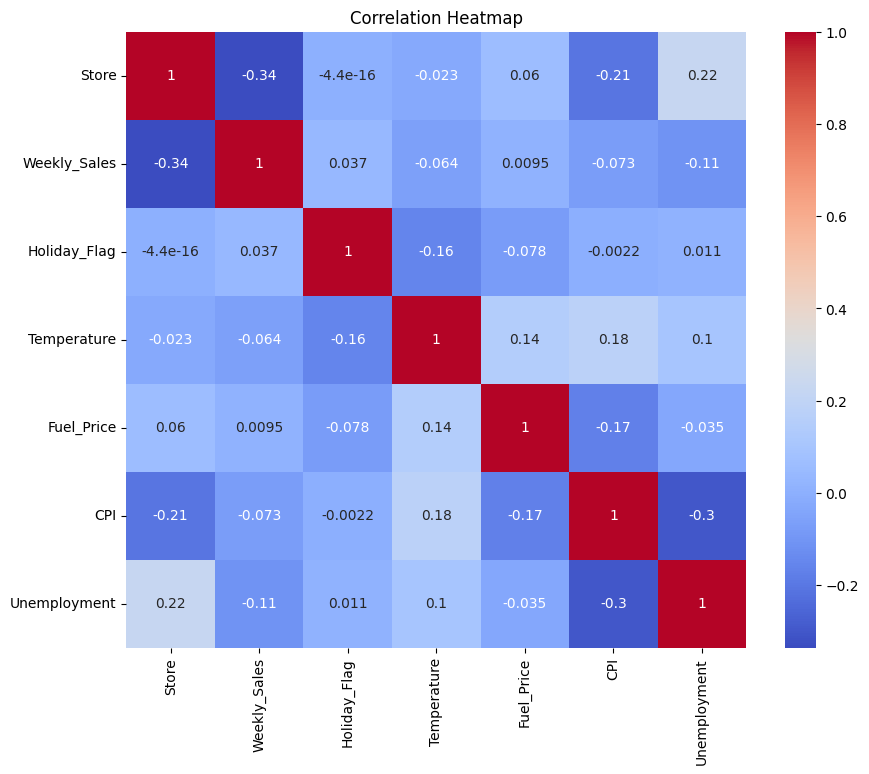

In [18]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

### Step 17 — Temperature vs Sales

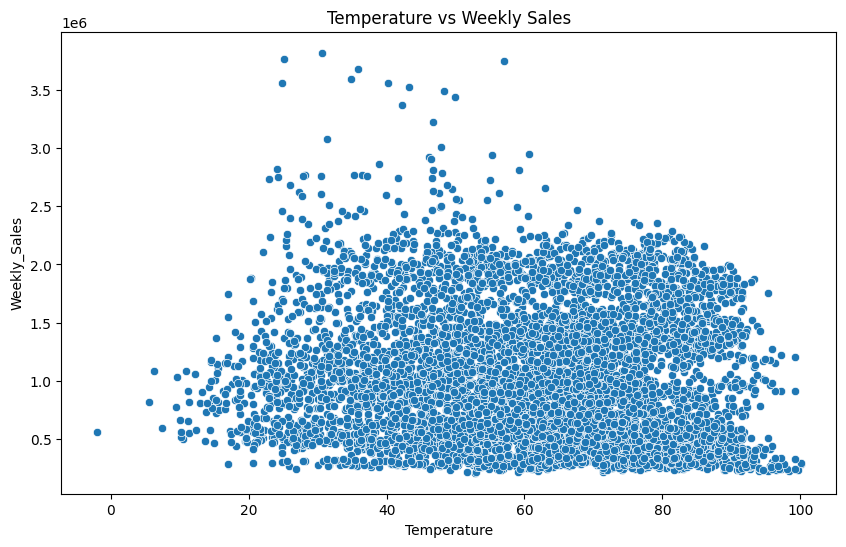

In [19]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="Temperature",
    y="Weekly_Sales",
    data=df
)

plt.title("Temperature vs Weekly Sales")

plt.show()

### Step 18 — Fuel Price vs Sales

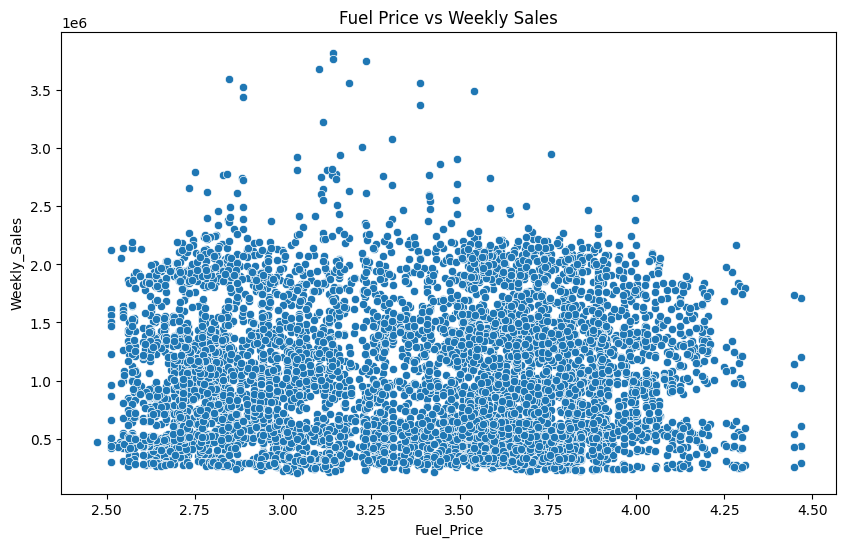

In [20]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="Fuel_Price",
    y="Weekly_Sales",
    data=df
)

plt.title("Fuel Price vs Weekly Sales")

plt.show()

## PHASE 2 — Forecasting Feature Engineering

### Step 1 — Extract Time Features

#### Year Feature

In [21]:
df["Year"] = df["Date"].dt.year

#### Month Feature

In [22]:
df["Month"] = df["Date"].dt.month

#### Week Feature

In [23]:
df["Week"] = df["Date"].dt.isocalendar().week

#### Day Feature

In [24]:
df["Day"] = df["Date"].dt.day

#### Quarter Feature

In [25]:
df["Quarter"] = df["Date"].dt.quarter

### Step 2 — Create Lag Feature

#### Previous Week Sales

This captures:
- sales continuity
- trend momentum

In [28]:
df["Previous_Week_Sales"] = df.groupby(
    "Store"
)["Weekly_Sales"].shift(1)

### Step 3 — Rolling Average Feature

#### 4-Week Moving Average

Captures:
- recent demand trend
- smoothing fluctuations
- demand momentum

In [29]:
df["Rolling_Mean_4"] = df.groupby(
    "Store"
)["Weekly_Sales"].transform(
    lambda x: x.shift(1).rolling(window=4).mean()
)

### Step 4 — Handle New Missing Values

#### Check Missing Values

In [30]:
df.isnull().sum()

Store                    0
Date                     0
Weekly_Sales             0
Holiday_Flag             0
Temperature              0
Fuel_Price               0
CPI                      0
Unemployment             0
Year                     0
Month                    0
Week                     0
Day                      0
Quarter                  0
Previous_Week_Sales     45
Rolling_Mean_4         180
dtype: int64

#### Fill Missing Values

In [31]:
df.fillna(method="bfill", inplace=True)

C:\Users\karth\AppData\Local\Temp\ipykernel_26732\1916524838.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method="bfill", inplace=True)


### Step 5 — Drop Date Column

In [32]:
df.drop("Date", axis=1, inplace=True)

### Step 6 — Correlation Heatmap

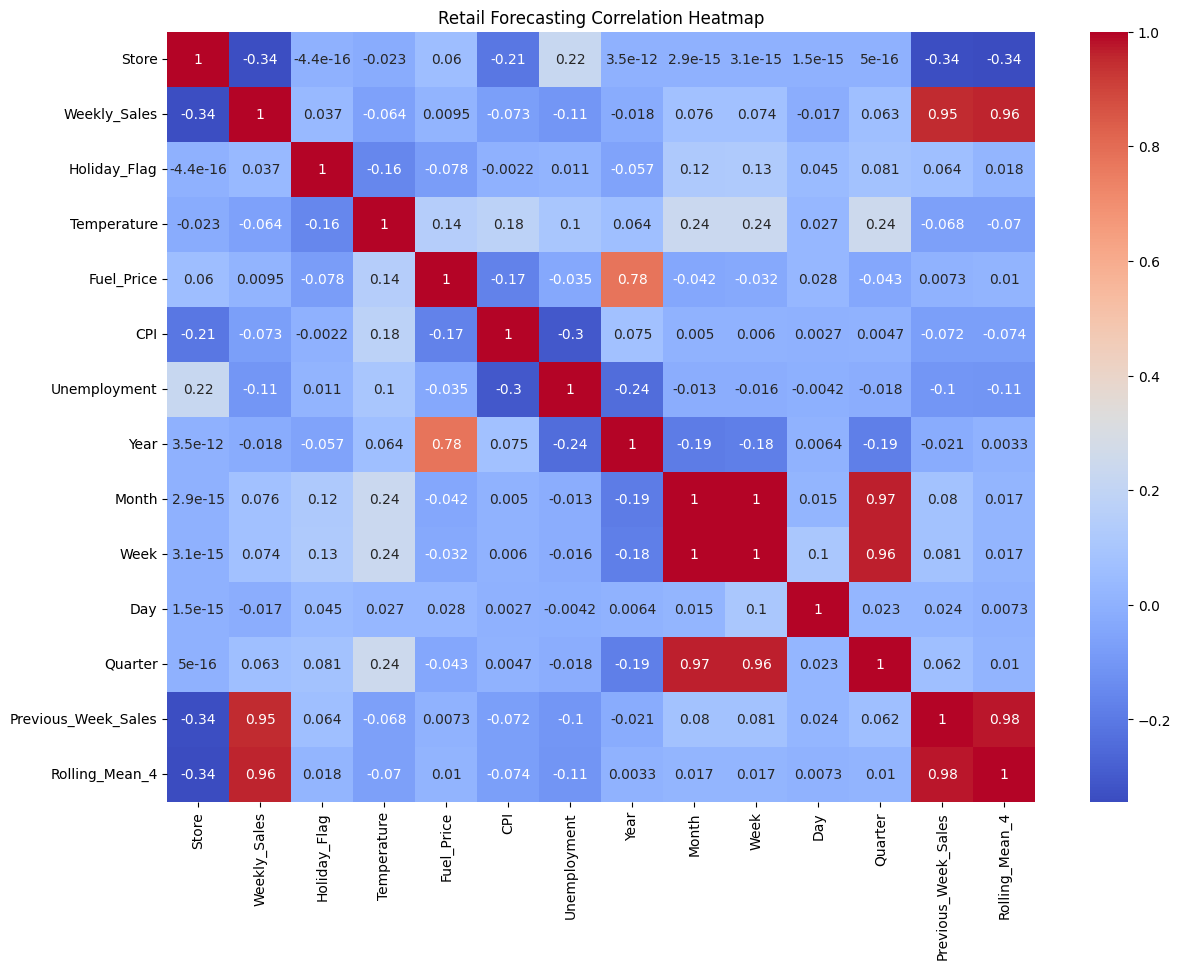

In [33]:
plt.figure(figsize=(14,10))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Retail Forecasting Correlation Heatmap")

plt.show()

### Step 7 — Features & Target

#### Features

In [34]:
X = df.drop("Weekly_Sales", axis=1)

#### Target

In [35]:
y = df["Weekly_Sales"]

### Step 8 — Train-Test Split

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=False
)

## PHASE 3 — Retail Demand Forecasting Model

### ✅ Random Forest Regressor

Why?
- handles nonlinear retail demand patterns
- robust for structured forecasting data
- stable predictions
- strong feature importance analysis

### Step 1 — Import Algorithm

In [37]:
from sklearn.ensemble import RandomForestRegressor

### Step 2 — Create Model

In [38]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

| Parameter        | Meaning                  |
| ---------------- | ------------------------ |
| n_estimators=300 | Number of decision trees |
| max_depth=20     | Controls complexity      |
| n_jobs=-1        | Uses all CPU cores       |
| random_state=42  | Reproducible results     |


### Step 3 — Train Model

In [39]:
rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'squared_error'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### Step 4 — Predict Test Data

In [40]:
y_pred = rf_model.predict(X_test)

### Step 5 — Import Evaluation Metrics

In [41]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

### Step 6 — Calculate Metrics

In [42]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

### Step 7 — Print Results

In [43]:
print("Retail Demand Forecasting Results")

print("MAE :", mae)

print("RMSE:", rmse)

print("R2 Score:", r2)

Retail Demand Forecasting Results
MAE : 42930.859636897694
RMSE: 62715.19178732011
R2 Score: 0.9740139132426203


### Step 8 — Feature Importance

#### Create Importance DataFrame

In [44]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(15))

                Feature  Importance
12       Rolling_Mean_4    0.724201
11  Previous_Week_Sales    0.220196
8                  Week    0.027811
9                   Day    0.014706
2           Temperature    0.002310
4                   CPI    0.002169
5          Unemployment    0.002048
3            Fuel_Price    0.001594
1          Holiday_Flag    0.001588
0                 Store    0.001508
7                 Month    0.001285
10              Quarter    0.000310
6                  Year    0.000274


### Step 9 — Visualize Feature Importance

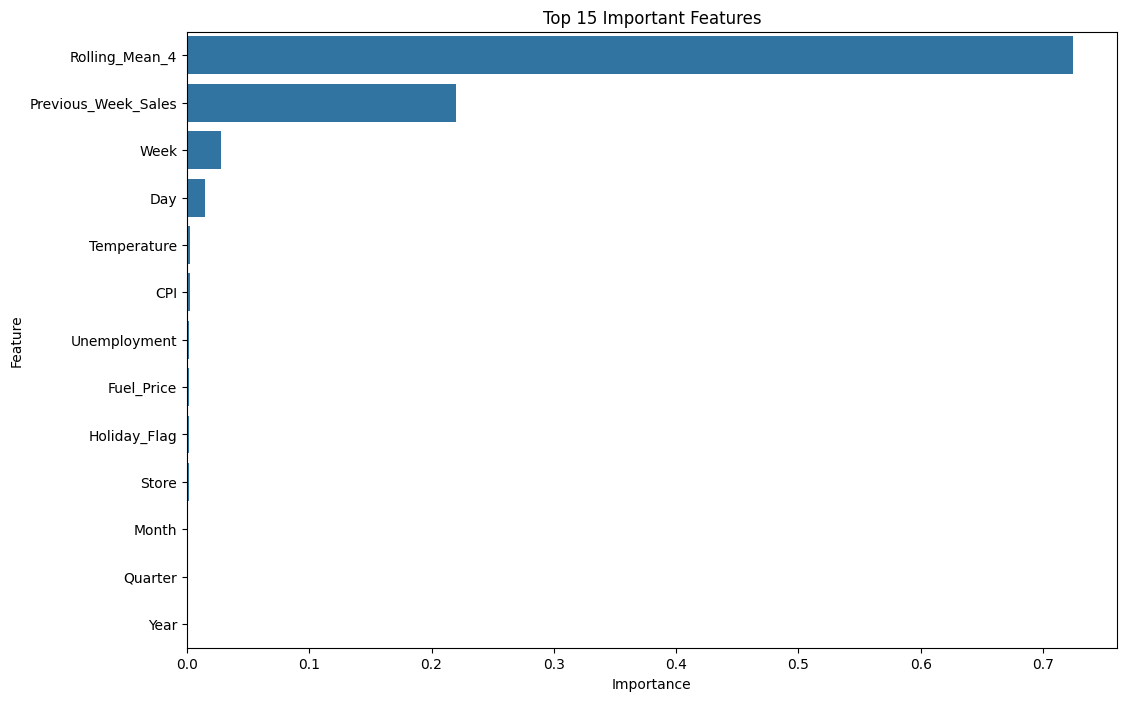

In [45]:
plt.figure(figsize=(12,8))

sns.barplot(
    x=importance["Importance"][:15],
    y=importance["Feature"][:15]
)

plt.title("Top 15 Important Features")

plt.show()

### Step 10 — Actual vs Predicted Visualization

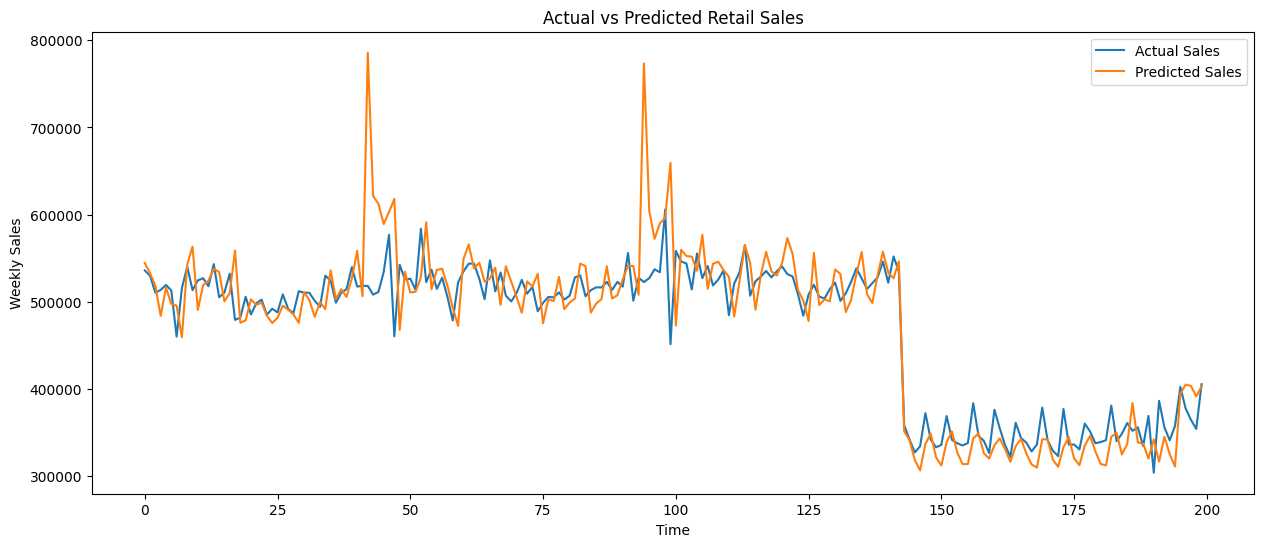

In [46]:
plt.figure(figsize=(15,6))

plt.plot(
    y_test.values[:200],
    label="Actual Sales"
)

plt.plot(
    y_pred[:200],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Retail Sales")

plt.xlabel("Time")

plt.ylabel("Weekly Sales")

plt.legend()

plt.show()

**Interpretation**

Good forecasting model:<br>
✅ predicted line follows actual trend

Bad forecasting:<br>
❌ completely random deviation

## PHASE 4 — Future Retail Demand Prediction System

### Step 1 — Create New Future Input Data

In [47]:
new_data = pd.DataFrame({
    "Store": [10],
    "Holiday_Flag": [1],
    "Temperature": [72],
    "Fuel_Price": [3.5],
    "CPI": [210],
    "Unemployment": [6.2],

    "Year": [2013],
    "Month": [11],
    "Week": [45],
    "Day": [7],
    "Quarter": [4],

    "Previous_Week_Sales": [1500000],

    "Rolling_Mean_4": [1450000]
})

### Step 2 — Match Training Columns

In [48]:
new_data = new_data[X.columns]

### Step 3 — Predict Future Sales

In [49]:
future_prediction = rf_model.predict(new_data)

### Step 4 — Display Forecast

In [50]:
print("Predicted Future Weekly Sales:")

print(future_prediction[0])

Predicted Future Weekly Sales:
1564443.7412750004


### Project Summary

This Project Includes:<br>
✅ Time-series preprocessing<br>
✅ Forecasting feature engineering<br>
✅ Lag features<br>
✅ Rolling averages<br>
✅ Random Forest forecasting<br>
✅ Business insights<br>
✅ Future demand prediction system<br>